In [3]:
import zipfile
import os

zip_path = "/content/bank+marketing.zip"
extract_path = "/content/bank_marketing"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/bank_marketing/bank.zip
/content/bank_marketing/bank-additional.zip
/content/bank_marketing/bank-additional/__MACOSX/._bank-additional
/content/bank_marketing/bank-additional/__MACOSX/bank-additional/._.DS_Store
/content/bank_marketing/bank-additional/bank-additional/bank-additional.csv
/content/bank_marketing/bank-additional/bank-additional/bank-additional-full.csv
/content/bank_marketing/bank-additional/bank-additional/bank-additional-names.txt
/content/bank_marketing/bank-additional/bank-additional/.DS_Store
/content/bank_marketing/bank-additional/bank-additional/.Rhistory
/content/bank_marketing/bank/bank.csv
/content/bank_marketing/bank/bank-full.csv
/content/bank_marketing/bank/bank-names.txt


In [4]:
import zipfile
import os

for filename in ["bank.zip", "bank-additional.zip"]:
    zip_path = os.path.join("/content/bank_marketing", filename)
    extract_path = os.path.join(
        "/content/bank_marketing",
        filename.replace(".zip", "")
    )

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print(f"\nFiles inside {filename}:")
    for root, dirs, files in os.walk(extract_path):
        for file in files:
            print(os.path.join(root, file))


Files inside bank.zip:
/content/bank_marketing/bank/bank.csv
/content/bank_marketing/bank/bank-full.csv
/content/bank_marketing/bank/bank-names.txt

Files inside bank-additional.zip:
/content/bank_marketing/bank-additional/__MACOSX/._bank-additional
/content/bank_marketing/bank-additional/__MACOSX/bank-additional/._.DS_Store
/content/bank_marketing/bank-additional/bank-additional/bank-additional.csv
/content/bank_marketing/bank-additional/bank-additional/bank-additional-full.csv
/content/bank_marketing/bank-additional/bank-additional/bank-additional-names.txt
/content/bank_marketing/bank-additional/bank-additional/.DS_Store
/content/bank_marketing/bank-additional/bank-additional/.Rhistory


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/bank_marketing/bank/bank-full.csv"

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [6]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Column Distribution:")
print(df["y"].value_counts())

print("\nTarget Column Percentage:")
print(df["y"].value_counts(normalize=True) * 100)

Dataset Shape: (45211, 17)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Missing Values:
age          0
job          0
mari

In [7]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Check the cleaned dataset
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum().sum())

print("\nFinal Dataset Preview:")
display(df_clean.head())

Original Dataset Shape: (45211, 17)
Cleaned Dataset Shape: (45211, 17)

Missing Values After Cleaning:
0

Final Dataset Preview:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [8]:
# Total customers contacted
total_customers = len(df_clean)

# Customers who subscribed
converted = (df_clean["y"] == "yes").sum()

# Customers who did not subscribe
not_converted = (df_clean["y"] == "no").sum()

# Calculate conversion rate
conversion_rate = (converted / total_customers) * 100
non_conversion_rate = (not_converted / total_customers) * 100

print("Total Customers:", total_customers)
print("Converted Customers:", converted)
print("Non-Converted Customers:", not_converted)
print(f"Conversion Rate: {conversion_rate:.2f}%")
print(f"Non-Conversion Rate: {non_conversion_rate:.2f}%")

Total Customers: 45211
Converted Customers: 5289
Non-Converted Customers: 39922
Conversion Rate: 11.70%
Non-Conversion Rate: 88.30%


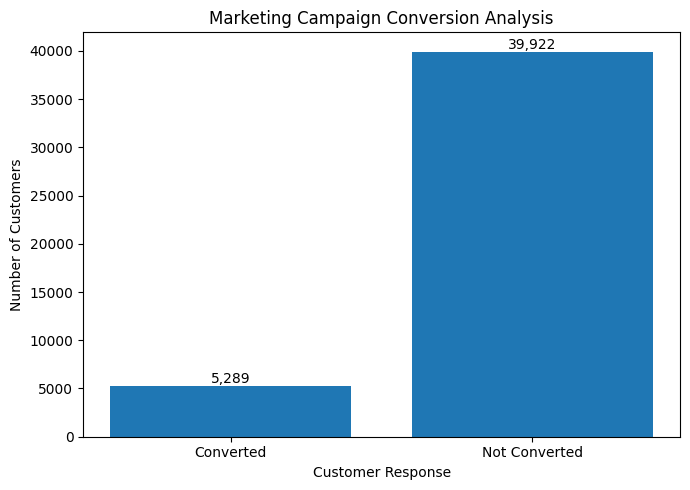

In [9]:
# Customer conversion counts
conversion_counts = df_clean["y"].value_counts().reindex(
    ["yes", "no"], fill_value=0
)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Converted", "Not Converted"],
    conversion_counts.values
)

plt.title("Marketing Campaign Conversion Analysis")
plt.xlabel("Customer Response")
plt.ylabel("Number of Customers")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

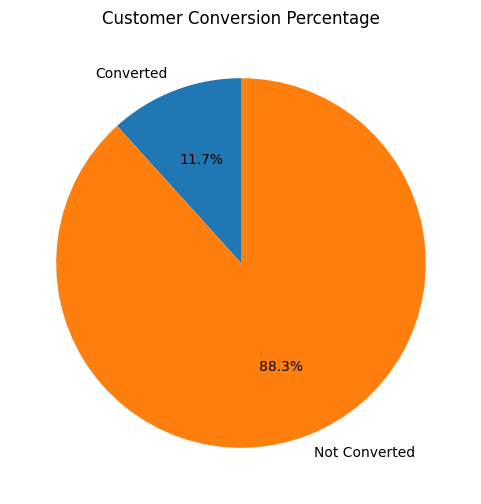

In [10]:
plt.figure(figsize=(6, 6))

plt.pie(
    [converted, not_converted],
    labels=["Converted", "Not Converted"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Conversion Percentage")
plt.show()

In [11]:
# Conversion rate by contact method
contact_analysis = df_clean.groupby("contact").agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

contact_analysis["Conversion_Rate"] = (
    contact_analysis["Converted_Customers"]
    / contact_analysis["Total_Customers"] * 100
)

contact_analysis = contact_analysis.sort_values(
    "Conversion_Rate", ascending=False
)

display(contact_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
contact,,,
cellular,29285,4369,14.92
telephone,2906,390,13.42
unknown,13020,530,4.07


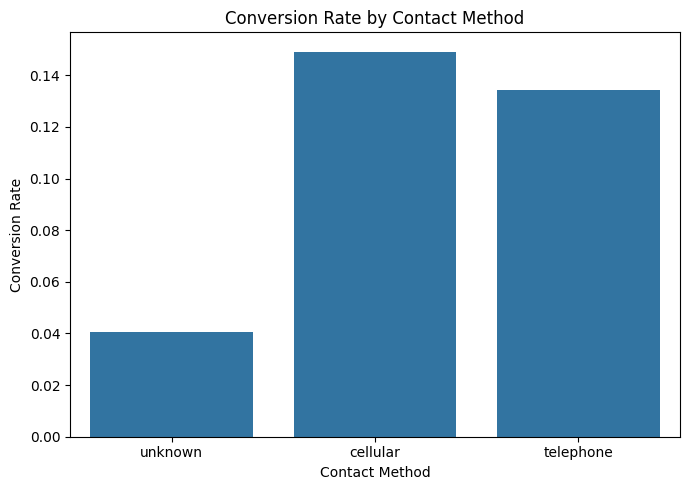

In [12]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df_clean,
    x="contact",
    y=df_clean["y"].eq("yes").astype(int),
    errorbar=None
)

plt.title("Conversion Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Conversion Rate")
plt.tight_layout()
plt.show()

In [13]:
month_analysis = df_clean.groupby("month").agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

month_analysis["Conversion_Rate"] = (
    month_analysis["Converted_Customers"]
    / month_analysis["Total_Customers"] * 100
)

display(month_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
month,,,
apr,2932,577,19.68
aug,6247,688,11.01
dec,214,100,46.73
feb,2649,441,16.65
jan,1403,142,10.12
jul,6895,627,9.09
jun,5341,546,10.22
mar,477,248,51.99
may,13766,925,6.72


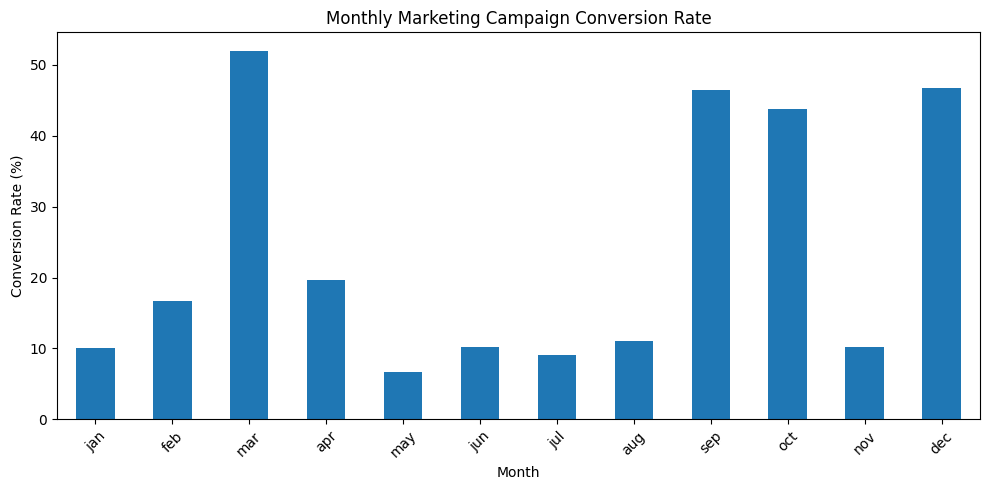

In [14]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly_rates = month_analysis.reindex(month_order)["Conversion_Rate"]

plt.figure(figsize=(10, 5))
monthly_rates.plot(kind="bar")

plt.title("Monthly Marketing Campaign Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
job_analysis = df_clean.groupby("job").agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

job_analysis["Conversion_Rate"] = (
    job_analysis["Converted_Customers"]
    / job_analysis["Total_Customers"] * 100
)

job_analysis = job_analysis.sort_values(
    "Conversion_Rate", ascending=False
)

display(job_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


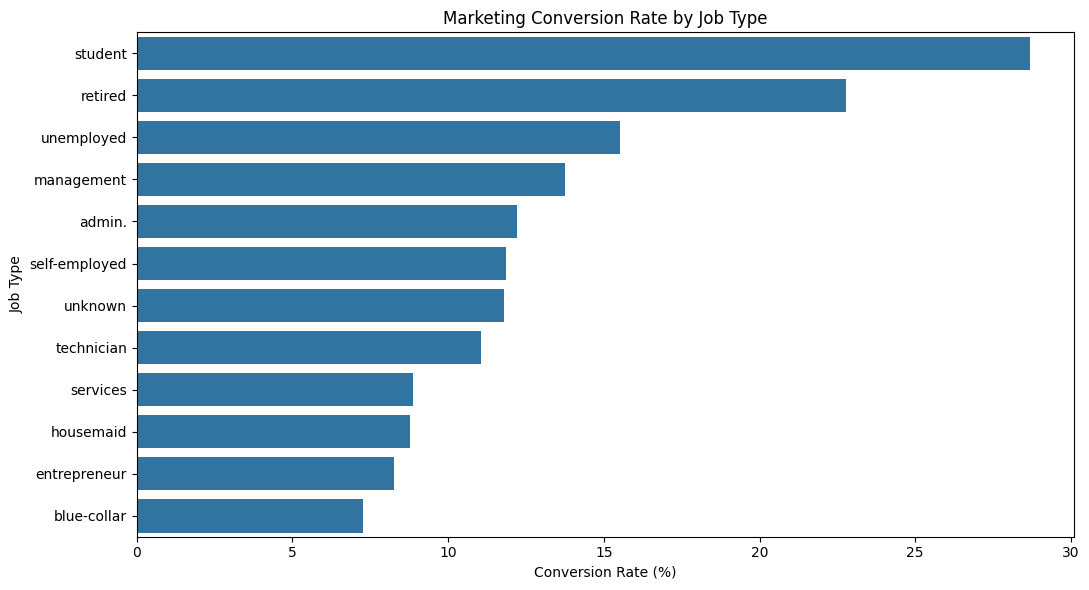

In [16]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=job_analysis.reset_index(),
    x="Conversion_Rate",
    y="job"
)

plt.title("Marketing Conversion Rate by Job Type")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Job Type")
plt.tight_layout()
plt.show()

In [17]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

age_analysis = df_clean.groupby(
    "age_group", observed=False
).agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

age_analysis["Conversion_Rate"] = (
    age_analysis["Converted_Customers"]
    / age_analysis["Total_Customers"] * 100
)

display(age_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
age_group,,,
18-25,1336,320,23.95
26-35,15571,1869,12.00
36-45,13856,1301,9.39
46-55,9548,893,9.35
56+,4900,906,18.49


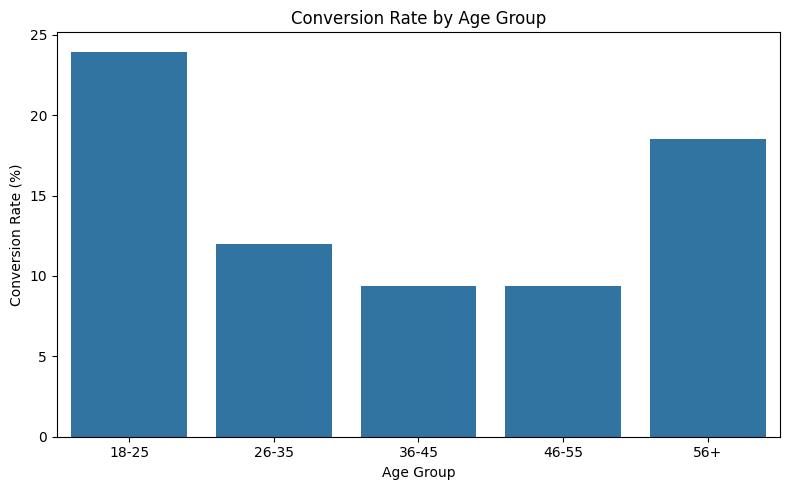

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_analysis.reset_index(),
    x="age_group",
    y="Conversion_Rate"
)

plt.title("Conversion Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

In [19]:
previous_analysis = df_clean.groupby("poutcome").agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

previous_analysis["Conversion_Rate"] = (
    previous_analysis["Converted_Customers"]
    / previous_analysis["Total_Customers"] * 100
)

previous_analysis = previous_analysis.sort_values(
    "Conversion_Rate", ascending=False
)

display(previous_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
poutcome,,,
success,1511,978,64.73
other,1840,307,16.68
failure,4901,618,12.61
unknown,36959,3386,9.16


In [20]:
previous_analysis = df_clean.groupby("poutcome").agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

previous_analysis["Conversion_Rate"] = (
    previous_analysis["Converted_Customers"]
    / previous_analysis["Total_Customers"] * 100
)

previous_analysis = previous_analysis.sort_values(
    "Conversion_Rate", ascending=False
)

display(previous_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
poutcome,,,
success,1511,978,64.73
other,1840,307,16.68
failure,4901,618,12.61
unknown,36959,3386,9.16


In [21]:
# Group number of contacts into categories
df_clean["campaign_group"] = pd.cut(
    df_clean["campaign"],
    bins=[0, 1, 2, 3, 5, float("inf")],
    labels=["1", "2", "3", "4-5", "6+"]
)

campaign_analysis = df_clean.groupby(
    "campaign_group", observed=False
).agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

campaign_analysis["Conversion_Rate"] = (
    campaign_analysis["Converted_Customers"]
    / campaign_analysis["Total_Customers"] * 100
)

display(campaign_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
campaign_group,,,
1,17544,2561,14.60
2,12505,1401,11.20
3,5521,618,11.19
4-5,5286,456,8.63
6+,4355,253,5.81


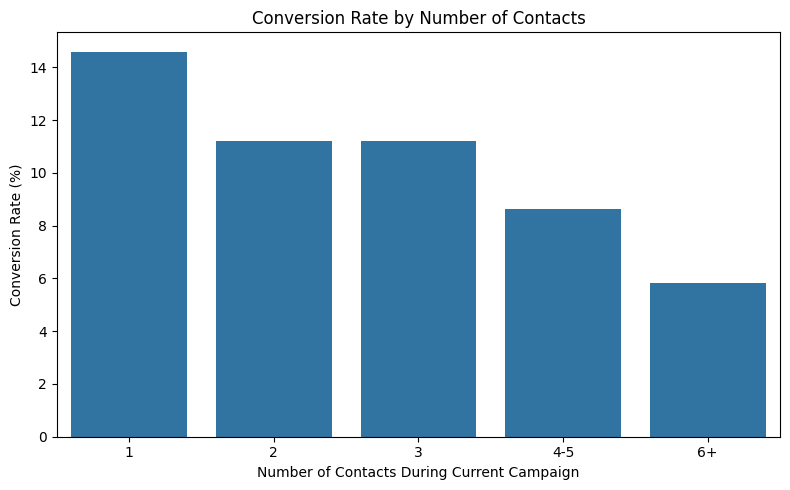

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=campaign_analysis.reset_index(),
    x="campaign_group",
    y="Conversion_Rate"
)

plt.title("Conversion Rate by Number of Contacts")
plt.xlabel("Number of Contacts During Current Campaign")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

In [23]:
df_clean["balance_group"] = pd.cut(
    df_clean["balance"],
    bins=[-float("inf"), 0, 1000, 5000, 10000, float("inf")],
    labels=["Negative", "0-1000", "1001-5000", "5001-10000", "10000+"]
)

balance_analysis = df_clean.groupby(
    "balance_group", observed=False
).agg(
    Total_Customers=("y", "count"),
    Converted_Customers=("y", lambda x: (x == "yes").sum())
)

balance_analysis["Conversion_Rate"] = (
    balance_analysis["Converted_Customers"]
    / balance_analysis["Total_Customers"] * 100
)

display(balance_analysis.round(2))

,Total_Customers,Converted_Customers,Conversion_Rate
balance_group,,,
Negative,7280,502,6.90
0-1000,23300,2539,10.90
1001-5000,11786,1807,15.33
5001-10000,2016,306,15.18
10000+,829,135,16.28


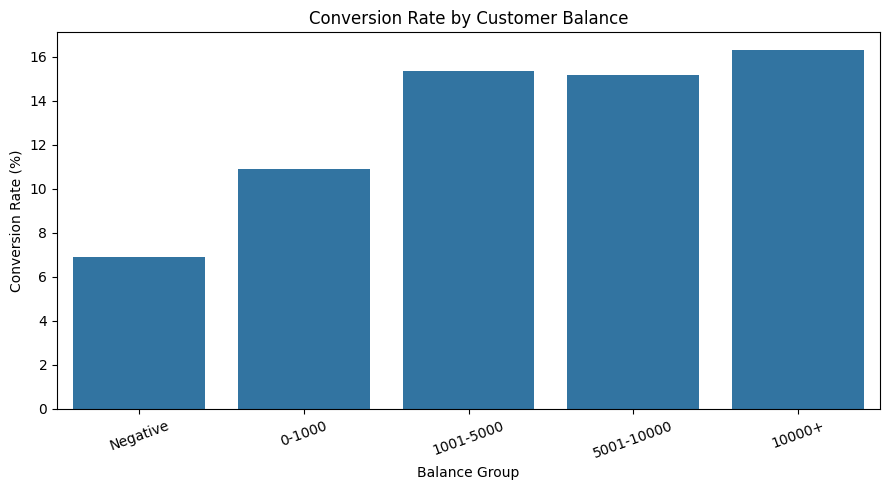

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=balance_analysis.reset_index(),
    x="balance_group",
    y="Conversion_Rate"
)

plt.title("Conversion Rate by Customer Balance")
plt.xlabel("Balance Group")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

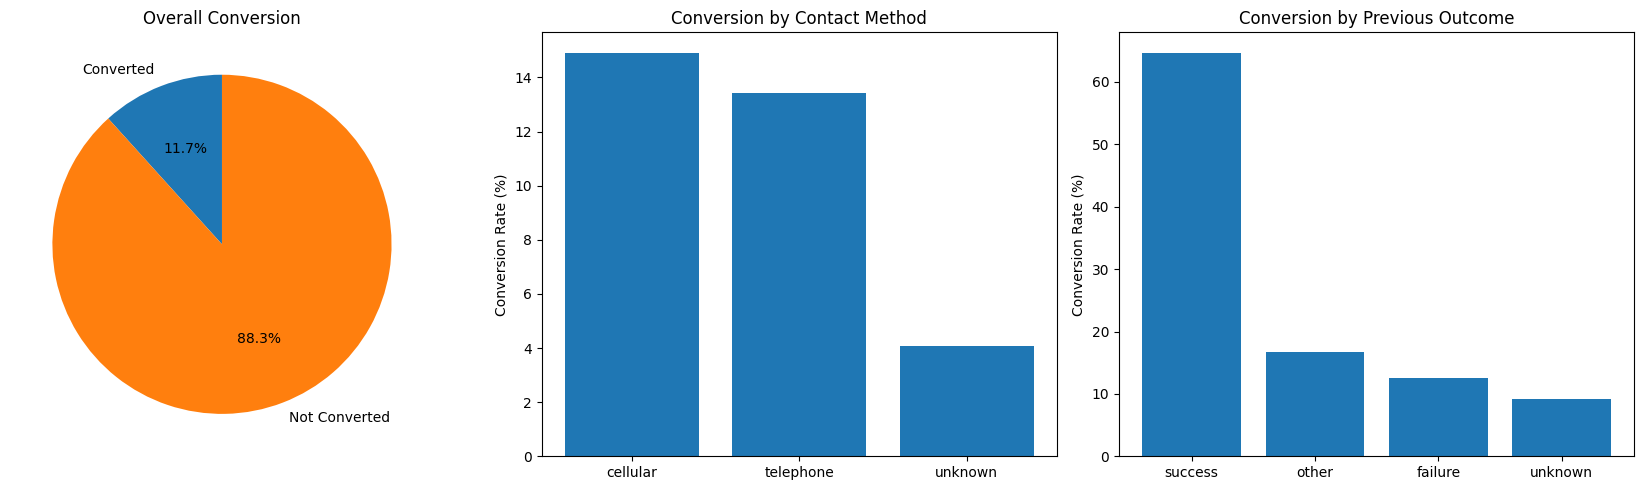

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Overall conversion
axes[0].pie(
    [converted, not_converted],
    labels=["Converted", "Not Converted"],
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Overall Conversion")

# Contact method
contact_rates = contact_analysis["Conversion_Rate"]
axes[1].bar(contact_rates.index, contact_rates.values)
axes[1].set_title("Conversion by Contact Method")
axes[1].set_ylabel("Conversion Rate (%)")

# Previous outcome
previous_rates = previous_analysis["Conversion_Rate"]
axes[2].bar(previous_rates.index, previous_rates.values)
axes[2].set_title("Conversion by Previous Outcome")
axes[2].set_ylabel("Conversion Rate (%)")

plt.tight_layout()
plt.show()

In [27]:
# Overall campaign results
total = len(df_clean)
yes_count = (df_clean["y"] == "yes").sum()
no_count = (df_clean["y"] == "no").sum()

print("========== OVERALL CAMPAIGN RESULTS ==========")
print("Total Customers:", total)
print("Successful Conversions:", yes_count)
print("Unsuccessful Conversions:", no_count)
print(f"Overall Conversion Rate: {yes_count / total * 100:.2f}%")

# Best and lowest conversion by contact method
contact_rates = (
    df_clean.assign(converted=df_clean["y"].eq("yes"))
    .groupby("contact")["converted"].mean() * 100
)

print("\n========== CONTACT METHOD ==========")
print("Highest conversion:", contact_rates.idxmax(),
      f"({contact_rates.max():.2f}%)")
print("Lowest conversion:", contact_rates.idxmin(),
      f"({contact_rates.min():.2f}%)")

# Best and lowest month
month_rates = (
    df_clean.assign(converted=df_clean["y"].eq("yes"))
    .groupby("month")["converted"].mean() * 100
)

print("\n========== MONTHLY PERFORMANCE ==========")
print("Highest conversion month:", month_rates.idxmax(),
      f"({month_rates.max():.2f}%)")
print("Lowest conversion month:", month_rates.idxmin(),
      f"({month_rates.min():.2f}%)")

# Previous campaign outcome
outcome_rates = (
    df_clean.assign(converted=df_clean["y"].eq("yes"))
    .groupby("poutcome")["converted"].mean() * 100
)

print("\n========== PREVIOUS CAMPAIGN OUTCOME ==========")
print(outcome_rates.round(2).to_string())

========== OVERALL CAMPAIGN RESULTS ==========
Total Customers: 45211
Successful Conversions: 5289
Unsuccessful Conversions: 39922
Overall Conversion Rate: 11.70%

========== CONTACT METHOD ==========
Highest conversion: cellular (14.92%)
Lowest conversion: unknown (4.07%)

========== MONTHLY PERFORMANCE ==========
Highest conversion month: mar (51.99%)
Lowest conversion month: may (6.72%)

========== PREVIOUS CAMPAIGN OUTCOME ==========
poutcome
failure    12.61
other      16.68
success    64.73
unknown     9.16


In [28]:
print("Top 5 job groups by conversion rate:")
display(job_analysis.head(5).round(2))

print("Bottom 5 job groups by conversion rate:")
display(job_analysis.tail(5).sort_values("Conversion_Rate").round(2))

Top 5 job groups by conversion rate:


,Total_Customers,Converted_Customers,Conversion_Rate
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20


Bottom 5 job groups by conversion rate:


,Total_Customers,Converted_Customers,Conversion_Rate
job,,,
blue-collar,9732,708,7.27
entrepreneur,1487,123,8.27
housemaid,1240,109,8.79
services,4154,369,8.88
technician,7597,840,11.06


# Marketing Campaign Analysis — Final Business Insights

## 1. Overall Campaign Performance
The dataset contains 45,211 customer records. Among them, 5,289 customers subscribed to the term deposit, resulting in an overall conversion rate of 11.70%.

## 2. Contact Method
The cellular contact method recorded a conversion rate of 14.92%, while the unknown contact category recorded 4.07%. Maintaining accurate contact information and evaluating channel performance may help improve future campaigns.

## 3. Monthly Performance
March recorded the highest conversion rate at 51.99%, while May recorded the lowest at 6.72%. Further investigation is needed to understand the reasons behind this difference.

## 4. Previous Campaign Outcome
Customers with a successful previous campaign outcome had a conversion rate of 64.73%, compared with 12.61% for failure, 16.68% for other, and 9.16% for unknown outcomes.

## 5. Job-wise Performance
Students recorded the highest job-group conversion rate at 28.68%, followed by retired customers at 22.79%. Blue-collar customers had the lowest rate among the listed groups at 7.27%.

## 6. Business Recommendations
- Evaluate cellular contact performance alongside campaign costs.
- Investigate the reasons for differences in monthly conversion rates.
- Test suitable campaign messages for different occupational groups.
- Use previous campaign outcomes to inform follow-up strategies.
- Avoid excessive repeated calls and respect customer preferences.
- Monitor conversion rate, total subscriptions, and campaign costs together.

## Conclusion
This project used Python, Pandas, Matplotlib, and Seaborn to analyze a bank marketing campaign dataset. It explored conversion rates by contact method, month, previous campaign outcome, and job group. The results can help inform campaign planning and customer targeting.

## Limitation
This dataset measures responses to a bank marketing campaign rather than a complete website visitor-to-lead funnel. The findings show associations and do not establish causation.

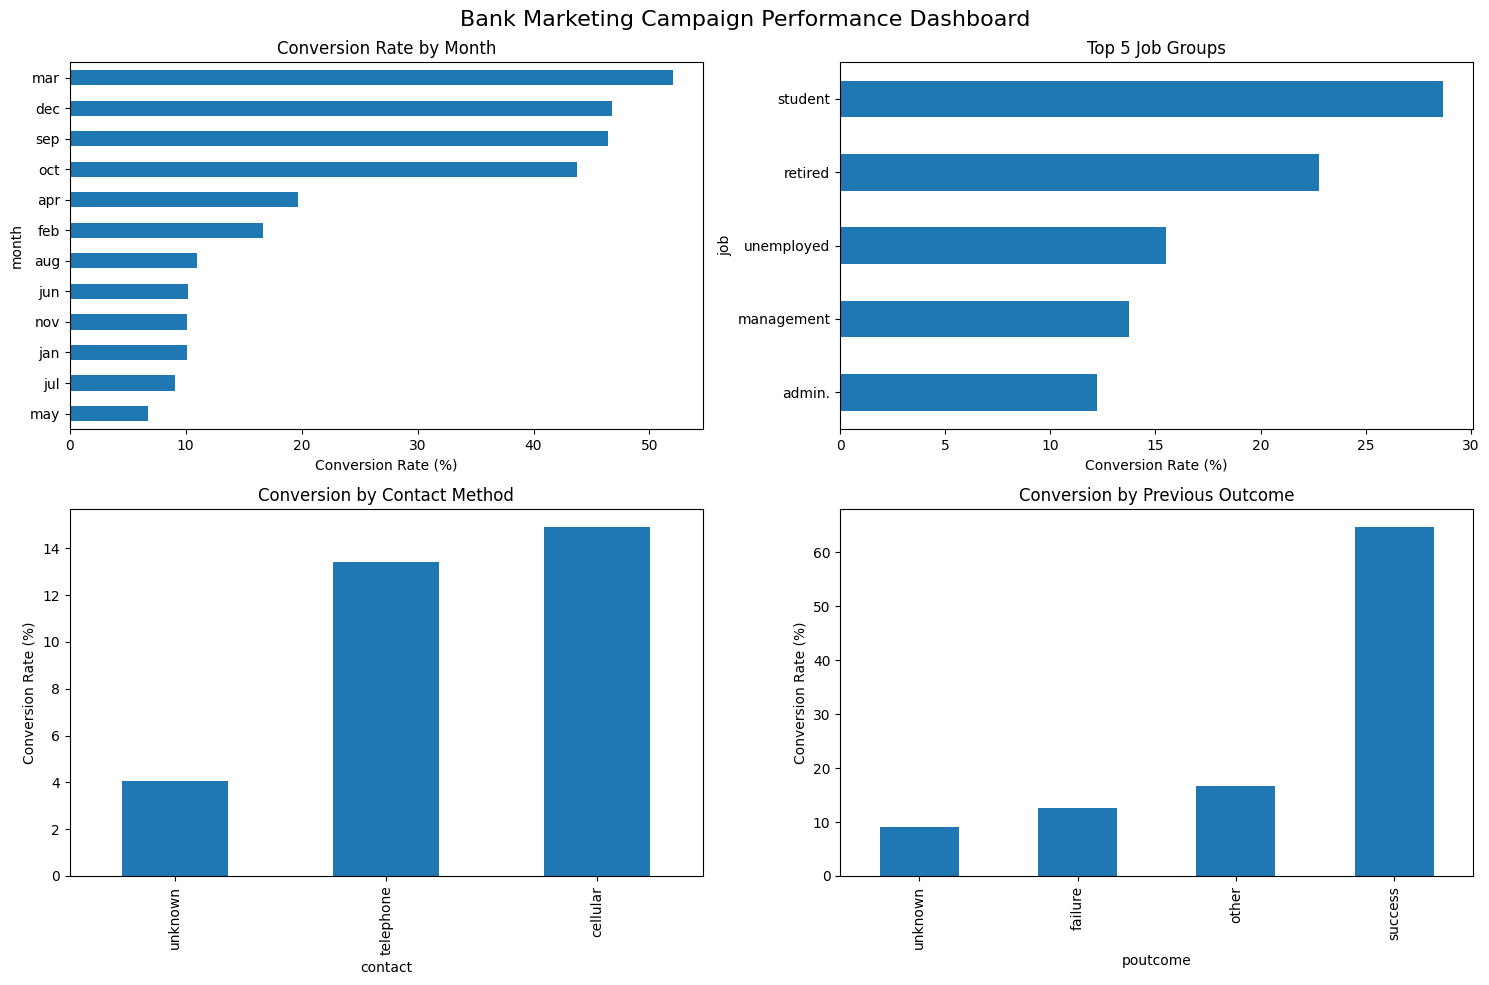

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

month_rates.sort_values().plot(kind="barh", ax=axes[0, 0])
axes[0, 0].set_title("Conversion Rate by Month")
axes[0, 0].set_xlabel("Conversion Rate (%)")

job_analysis.sort_values(
    "Conversion_Rate", ascending=True
).tail(5).plot(
    y="Conversion_Rate", kind="barh", ax=axes[0, 1],
    legend=False
)
axes[0, 1].set_title("Top 5 Job Groups")
axes[0, 1].set_xlabel("Conversion Rate (%)")

contact_rates.sort_values().plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Conversion by Contact Method")
axes[1, 0].set_ylabel("Conversion Rate (%)")

outcome_rates.sort_values().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Conversion by Previous Outcome")
axes[1, 1].set_ylabel("Conversion Rate (%)")

plt.suptitle("Bank Marketing Campaign Performance Dashboard", fontsize=16)
plt.tight_layout()
plt.show()